# ⚡ VOLTA — Track B: First LSTM (Day 2)

**Goal:** build a first, small LSTM that forecasts the electricity price (`price actual`) for the next 24 hours, using the previous 168 hours, and save its validation predictions so Track A can compare it with the simple baselines.

<div dir="rtl">

**الهدف:** بناء أول LSTM صغير يتوقع سعر الكهرباء (`price actual`) للـ 24 ساعة القادمة اعتمادًا على آخر 168 ساعة، وحفظ توقعاته على فترة التحقق حتى يقارنها Track A مع الـ baselines.

</div>

**Rules (Day 2) / القواعد**
- One target series, one horizon (24 h), no extra input columns today. / سلسلة هدف واحدة، أفق واحد، بدون أعمدة إضافية اليوم.
- Split by date, never randomly. Targets of a window stay inside their period. / التقسيم بالتاريخ، وأهداف كل نافذة داخل فترتها.
- Scaler is fitted on the training period only. / الـ scaler يتدرب على التدريب فقط.
- The Test period (2018) is **not used**. / فترة الاختبار (2018) **لا تُستخدم**.

**How to use / كيف تستخدمين الملف:** run the cells from top to bottom. / شغّلي الخلايا من الأعلى إلى الأسفل.

### Step 1 — Settings | الخطوة 1 — الإعدادات

In [20]:
from pathlib import Path
print("working folder:", Path.cwd())
print("file exists    :", Path("../data/processed/volta_clean_hourly.csv").exists())
print("data folder    :", [p.name for p in Path("../data").glob("*")] if Path("../data").exists() else "no ../data")

working folder: /home/rahaf/code/RahafAlrehaili/volta/notebooks
file exists    : True
data folder    : ['raw', 'processed']


In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# ---------------- Data ----------------
CANDIDATES = [                       # first file that exists is used
    "../data/processed/volta_clean_hourly.csv",
    "data/processed/volta_clean_hourly.csv",
    "volta_clean_hourly.csv",
]
TARGET = "price actual"

# ---------------- Forecast setup (same as Track A) ----------------
H = 24                               # forecast horizon (hours)
INPUT_WINDOW = 168                   # hours of history given to the LSTM
SEED = 42

# ---------------- Splits (UTC) ----------------
TRAIN_START = "2015-01-01"
TRAIN_END   = "2016-12-31"
VAL_START   = "2017-01-01"
VAL_END     = "2017-12-31"
# Test (2018) is NOT used in this notebook

# ---------------- Small LSTM ----------------
UNITS  = 32
EPOCHS = 10
BATCH  = 32

# ---------------- Output ----------------
OUT_FILE = "lstm_predictions_validation.csv"   # columns: issue_time, timestamp, lstm

DATA_PATH = next((p for p in CANDIDATES if Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("volta_clean_hourly.csv not found. Add its path to CANDIDATES.")
print("Data file:", DATA_PATH)

Data file: ../data/processed/volta_clean_hourly.csv


### Step 2 — Load the price series | الخطوة 2 — تحميل سلسلة السعر

We read the cleaned file, convert time to UTC, and keep only the price. The cleaned file has no missing values, and we check that the hourly grid is complete.

<div dir="rtl">

نقرأ الملف النظيف، ونحوّل الوقت إلى UTC، ونأخذ السعر فقط. الملف النظيف ما فيه قيم ناقصة، ونتأكد أن الشبكة الساعية كاملة.

</div>

In [22]:
raw = pd.read_csv(DATA_PATH, usecols=["time", TARGET])
raw["time"] = pd.to_datetime(raw["time"], utc=True)
price = raw.sort_values("time").set_index("time")[TARGET].astype(float)

# the LSTM needs a complete hourly grid and no missing values
full_index = pd.date_range(price.index.min(), price.index.max(), freq="h", tz="UTC")
assert len(full_index) == len(price), "Some hours are missing"
assert price.isna().sum() == 0, "Missing values in the price"

print("rows:", len(price), "| first:", price.index.min(), "| last:", price.index.max())

rows: 35064 | first: 2014-12-31 23:00:00+00:00 | last: 2018-12-31 22:00:00+00:00


### Step 3 — Split by date and choose forecast days | الخطوة 3 — التقسيم بالتاريخ وأيام التوقع

A forecast is issued every day at 00:00 UTC for the next 24 hours. The first training day needs 168 hours of history. The first validation day may use the end of the training period as input (it is the past), but its **targets** must be inside validation.

<div dir="rtl">

يصدر التوقع كل يوم الساعة 00:00 UTC للـ 24 ساعة القادمة. أول يوم تدريب يحتاج 168 ساعة سابقة. وأول يوم تحقق يقدر ياخذ مدخلاته من آخر التدريب (لأنها ماضي)، لكن **أهدافه** لازم تكون داخل فترة التحقق.

</div>

In [23]:
def utc(s):
    return pd.Timestamp(s, tz="UTC")

# same forecast days as Track A
first_train_day = utc(TRAIN_START) + pd.Timedelta(hours=INPUT_WINDOW)
train_days = pd.date_range(first_train_day, utc(TRAIN_END), freq="D")
val_days   = pd.date_range(utc(VAL_START), utc(VAL_END), freq="D")

# the last target hour of each period must stay inside the period
assert train_days[-1] + pd.Timedelta(hours=H - 1) < utc(VAL_START)
assert val_days[-1] + pd.Timedelta(hours=H - 1) < utc("2018-01-01")

print(f"Train      : {train_days[0].date()} -> {train_days[-1].date()}  ({len(train_days)} forecast days)")
print(f"Validation : {val_days[0].date()} -> {val_days[-1].date()}  ({len(val_days)} forecast days)")

Train      : 2015-01-08 -> 2016-12-31  (724 forecast days)
Validation : 2017-01-01 -> 2017-12-31  (365 forecast days)


### Step 4 — Scale the price (fit on training only) | الخطوة 4 — تحجيم السعر (على التدريب فقط)

The scaler learns min and max from the training period only. The same scaler is then applied to every row. Validation values may fall outside 0–1; that is normal.

<div dir="rtl">

الـ scaler يتعلم الأصغر والأكبر من فترة التدريب فقط، ثم نطبق نفسه على كل الصفوف. قيم التحقق ممكن تطلع خارج 0–1 وهذا طبيعي.

</div>

In [24]:
train_prices = price.loc[utc(TRAIN_START): utc(TRAIN_END) + pd.Timedelta(hours=23)]

scaler = MinMaxScaler().fit(train_prices.values.reshape(-1, 1))     # fit: training only
scaled = pd.Series(
    scaler.transform(price.values.reshape(-1, 1)).ravel(),          # transform: all rows
    index=price.index,
)
print("scaler min/max (EUR/MWh):", round(float(scaler.data_min_[0]), 2), "/", round(float(scaler.data_max_[0]), 2))

scaler min/max (EUR/MWh): 9.33 / 102.62


### Step 5 — Create the windows | الخطوة 5 — إنشاء النوافذ

For each forecast day `T`: **X** = the 168 hours before `T`, **y** = the 24 hours starting at `T`.

<div dir="rtl">

لكل يوم توقع `T`: **X** = الـ 168 ساعة قبل `T`، و**y** = الـ 24 ساعة بدءًا من `T`.

</div>

In [25]:
def make_windows(series, issue_days, past=INPUT_WINDOW, horizon=H):
    """X: past hours before the issue time; y: next `horizon` hours from the issue time."""
    X, y = [], []
    for T in issue_days:
        x_part = series.loc[T - pd.Timedelta(hours=past): T - pd.Timedelta(hours=1)].values
        y_part = series.loc[T: T + pd.Timedelta(hours=horizon - 1)].values
        assert len(x_part) == past and len(y_part) == horizon
        X.append(x_part)
        y.append(y_part)
    return np.array(X)[..., np.newaxis], np.array(y)       # X shape: (days, 168, 1)

X_train, y_train = make_windows(scaled, train_days)
X_val,   y_val   = make_windows(scaled, val_days)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "| y_val  :", y_val.shape)

X_train: (724, 168, 1) | y_train: (724, 24)
X_val  : (365, 168, 1) | y_val  : (365, 24)


### Step 6 — Hand check of windows | الخطوة 6 — فحص النوافذ يدويًا

We print the input and target times of the first training window and the first validation window, and assert that every input is before the issue time.

<div dir="rtl">

نطبع أوقات المدخلات والأهداف لأول نافذة تدريب وأول نافذة تحقق، ونتأكد أن كل المدخلات قبل وقت الإصدار.

</div>

In [26]:
for name, T in [("first train window", train_days[0]), ("first validation window", val_days[0])]:
    x_times = pd.date_range(T - pd.Timedelta(hours=INPUT_WINDOW), periods=INPUT_WINDOW, freq="h")
    y_times = pd.date_range(T, periods=H, freq="h")
    assert x_times.max() < T <= y_times.min(), "Inputs must come before targets"
    print(f"{name}")
    print(f"  inputs : {x_times.min()} -> {x_times.max()}")
    print(f"  targets: {y_times.min()} -> {y_times.max()}")

# check that the stored numbers really are the right hours (first validation window)
T = val_days[0]
assert np.allclose(X_val[0, :, 0], scaled.loc[T - pd.Timedelta(hours=INPUT_WINDOW): T - pd.Timedelta(hours=1)].values)
assert np.allclose(y_val[0], scaled.loc[T: T + pd.Timedelta(hours=H - 1)].values)
print("Windows verified: inputs come before targets.")

first train window
  inputs : 2015-01-01 00:00:00+00:00 -> 2015-01-07 23:00:00+00:00
  targets: 2015-01-08 00:00:00+00:00 -> 2015-01-08 23:00:00+00:00
first validation window
  inputs : 2016-12-25 00:00:00+00:00 -> 2016-12-31 23:00:00+00:00
  targets: 2017-01-01 00:00:00+00:00 -> 2017-01-01 23:00:00+00:00
Windows verified: inputs come before targets.


### Step 7 — Build the LSTM | الخطوة 7 — بناء الـ LSTM

One small LSTM layer, then a `Dense(24)` layer so the model returns all 24 hours at once.

<div dir="rtl">

طبقة LSTM صغيرة واحدة، ثم `Dense(24)` حتى يطلع المودل الـ 24 ساعة مرة وحدة.

</div>

In [27]:
from tensorflow import keras

keras.utils.set_random_seed(SEED)

model = keras.Sequential([
    keras.Input(shape=(INPUT_WINDOW, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(H),            # 24 outputs = next 24 hours
])
model.compile(optimizer="adam", loss="mae")
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

### Step 8 — Train | الخطوة 8 — التدريب

Short run (up to 30 epochs; early stopping stops when the validation error stops improving). We do not shuffle, so the time order is kept. Validation is used only to watch the error, not to train.

<div dir="rtl">

تدريب قصير (حتى 30 epoch، والـ early stopping يوقفه لما يتوقف تحسن خطأ التحقق). ما نخلط الترتيب حتى يبقى الوقت مرتبًا. والتحقق يستخدم لمراقبة الخطأ فقط، وليس للتدريب.

</div>

In [28]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # watch the validation error
    patience=3,                  # stop after 3 epochs without improvement
    restore_best_weights=True,   # go back to the best epoch
)

Epoch 1/1000
23/23 - 2s - 75ms/step - loss: 0.4180 - val_loss: 0.3202
Epoch 2/1000
23/23 - 1s - 32ms/step - loss: 0.2100 - val_loss: 0.1556
Epoch 3/1000
23/23 - 1s - 30ms/step - loss: 0.1354 - val_loss: 0.1520
Epoch 4/1000
23/23 - 1s - 29ms/step - loss: 0.1228 - val_loss: 0.1053
Epoch 5/1000
23/23 - 1s - 31ms/step - loss: 0.0995 - val_loss: 0.0939
Epoch 6/1000
23/23 - 1s - 30ms/step - loss: 0.0904 - val_loss: 0.0864
Epoch 7/1000
23/23 - 1s - 30ms/step - loss: 0.0839 - val_loss: 0.0781
Epoch 8/1000
23/23 - 1s - 31ms/step - loss: 0.0794 - val_loss: 0.0759
Epoch 9/1000
23/23 - 1s - 30ms/step - loss: 0.0778 - val_loss: 0.0749
Epoch 10/1000
23/23 - 1s - 31ms/step - loss: 0.0768 - val_loss: 0.0732
Epoch 11/1000
23/23 - 1s - 32ms/step - loss: 0.0756 - val_loss: 0.0707
Epoch 12/1000
23/23 - 1s - 27ms/step - loss: 0.0744 - val_loss: 0.0689
Epoch 13/1000
23/23 - 1s - 27ms/step - loss: 0.0735 - val_loss: 0.0679
Epoch 14/1000
23/23 - 1s - 29ms/step - loss: 0.0728 - val_loss: 0.0665
Epoch 15/1000
2

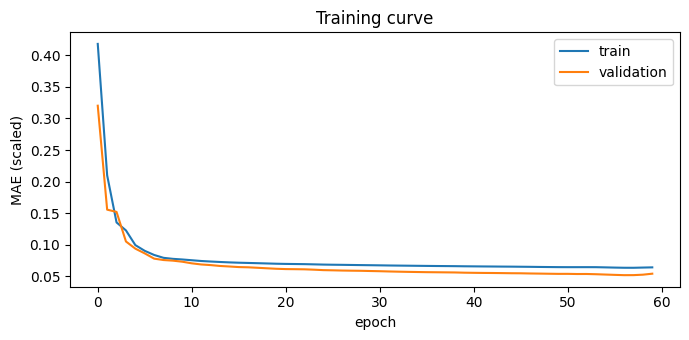

In [29]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,                   # upper limit; early stopping decides when to stop
    batch_size=BATCH,
    shuffle=False,
    callbacks=[early_stop],
    verbose=2,
)

plt.figure(figsize=(7, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MAE (scaled)"); plt.title("Training curve"); plt.legend()
plt.tight_layout(); plt.show()

### Step 9 — Predict and save | الخطوة 9 — التوقع والحفظ

Predictions are converted back to EUR/MWh and saved in the format Track A expects: `issue_time`, `timestamp`, `lstm`.

<div dir="rtl">

نرجّع التوقعات إلى EUR/MWh ونحفظها بالصيغة التي يتوقعها Track A: `issue_time` و `timestamp` و `lstm`.

</div>

In [30]:
pred_scaled = model.predict(X_val, verbose=0)                          # (days, 24)
pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)   # EUR/MWh

rows = []
for T, values in zip(val_days, pred):
    for k, v in enumerate(values):
        rows.append((T, T + pd.Timedelta(hours=k), float(v)))
lstm_df = pd.DataFrame(rows, columns=["issue_time", "timestamp", "lstm"])
lstm_df.to_csv(OUT_FILE, index=False)

print("saved:", OUT_FILE, "| rows:", len(lstm_df), "| forecast days:", lstm_df["issue_time"].nunique())
lstm_df.head(3)

saved: lstm_predictions_validation.csv | rows: 8760 | forecast days: 365


,issue_time,timestamp,lstm
0,2017-01-01 00:00:00+00:00,2017-01-01 00:00:00+00:00,59.896191
1,2017-01-01 00:00:00+00:00,2017-01-01 01:00:00+00:00,59.069416
2,2017-01-01 00:00:00+00:00,2017-01-01 02:00:00+00:00,55.847290


### Step 10 — Quick comparison with simple forecasts | الخطوة 10 — مقارنة سريعة مع التوقعات البسيطة

Same validation days, same horizon, same metric (MAE in EUR/MWh). The full comparison is done in the Track A notebook.

<div dir="rtl">

نفس أيام التحقق ونفس الأفق ونفس المقياس (MAE بوحدة EUR/MWh). المقارنة الكاملة تتم في نوتبوك Track A.

</div>

In [31]:
tgt_idx = lstm_df["timestamp"]
issue   = lstm_df["issue_time"]
comp = pd.DataFrame({
    "actual":     price.reindex(tgt_idx).values,
    "last_value": price.reindex(issue - pd.Timedelta(hours=1)).values,    # last known price at 00:00
    "lag_24":     price.reindex(tgt_idx - pd.Timedelta(hours=24)).values,
    "lag_168":    price.reindex(tgt_idx - pd.Timedelta(hours=168)).values,
    "lstm":       lstm_df["lstm"].values,
}).dropna()                                                               # same rows for every method

mae = {c: (comp["actual"] - comp[c]).abs().mean() for c in ["last_value", "lag_24", "lag_168", "lstm"]}
table = pd.DataFrame({"MAE (EUR/MWh)": mae}).round(2).sort_values("MAE (EUR/MWh)")
print("rows compared:", len(comp))
table

rows compared: 8760


,MAE (EUR/MWh)
lstm,4.85
lag_24,5.19
lag_168,6.27
last_value,7.56


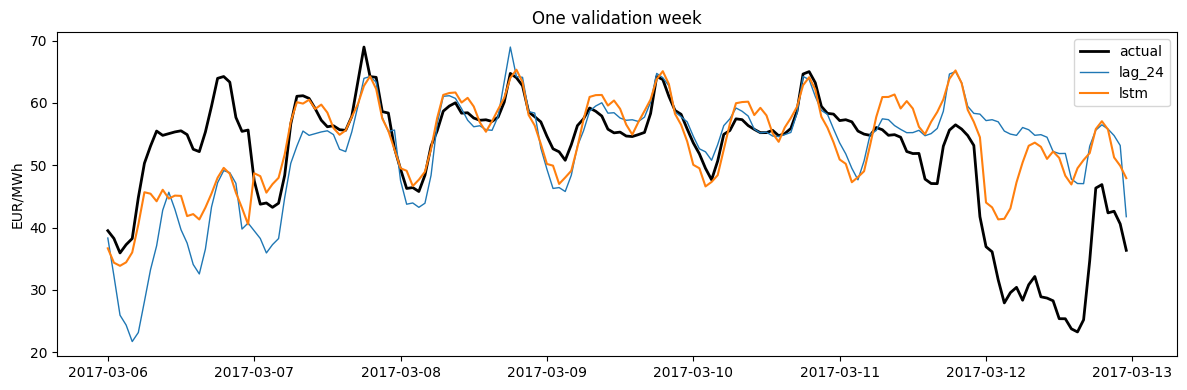

In [32]:
# one validation week: actual vs LSTM vs lag_24
week_start = utc("2017-03-06")
mask = (lstm_df["timestamp"] >= week_start) & (lstm_df["timestamp"] < week_start + pd.Timedelta(days=7))
w = lstm_df[mask].copy()
w["actual"] = price.reindex(w["timestamp"]).values
w["lag_24"] = price.reindex(w["timestamp"] - pd.Timedelta(hours=24)).values

plt.figure(figsize=(12, 4))
plt.plot(w["timestamp"], w["actual"], color="black", lw=2, label="actual")
plt.plot(w["timestamp"], w["lag_24"], lw=1, label="lag_24")
plt.plot(w["timestamp"], w["lstm"], lw=1.5, label="lstm")
plt.ylabel("EUR/MWh"); plt.title("One validation week"); plt.legend()
plt.tight_layout(); plt.show()

## Step 11 — GRU (same setup, only the layer changes) | الخطوة 11 — GRU (نفس الإعداد، الطبقة فقط تتغير)

GRU is a lighter relative of LSTM. To compare fairly we keep **everything else the same**: windows, scaler, `UNITS`, `SEED`, optimizer, early stopping. The predictions go to a **separate file**, so the LSTM file is not overwritten.

<div dir="rtl">

الـ GRU قريب من الـ LSTM لكنه أخف. وللمقارنة العادلة نخلي **كل شي ثاني نفسه**: النوافذ، والـ scaler، و`UNITS`، و`SEED`، والـ optimizer، والـ early stopping. والتوقعات تنحفظ في **ملف منفصل** حتى ما نكتب فوق ملف الـ LSTM.

</div>

Epoch 1/1000
23/23 - 2s - 81ms/step - loss: 0.4291 - val_loss: 0.3865
Epoch 2/1000
23/23 - 1s - 36ms/step - loss: 0.2471 - val_loss: 0.1334
Epoch 3/1000
23/23 - 1s - 36ms/step - loss: 0.1218 - val_loss: 0.1231
Epoch 4/1000
23/23 - 1s - 35ms/step - loss: 0.1070 - val_loss: 0.1002
Epoch 5/1000
23/23 - 1s - 35ms/step - loss: 0.0991 - val_loss: 0.0749
Epoch 6/1000
23/23 - 1s - 36ms/step - loss: 0.0882 - val_loss: 0.0715
Epoch 7/1000
23/23 - 1s - 37ms/step - loss: 0.0836 - val_loss: 0.0706
Epoch 8/1000
23/23 - 1s - 39ms/step - loss: 0.0810 - val_loss: 0.0688
Epoch 9/1000
23/23 - 1s - 46ms/step - loss: 0.0781 - val_loss: 0.0669
Epoch 10/1000
23/23 - 1s - 39ms/step - loss: 0.0752 - val_loss: 0.0645
Epoch 11/1000
23/23 - 1s - 37ms/step - loss: 0.0726 - val_loss: 0.0626
Epoch 12/1000
23/23 - 1s - 36ms/step - loss: 0.0708 - val_loss: 0.0608
Epoch 13/1000
23/23 - 1s - 36ms/step - loss: 0.0692 - val_loss: 0.0596
Epoch 14/1000
23/23 - 1s - 35ms/step - loss: 0.0682 - val_loss: 0.0587
Epoch 15/1000
2

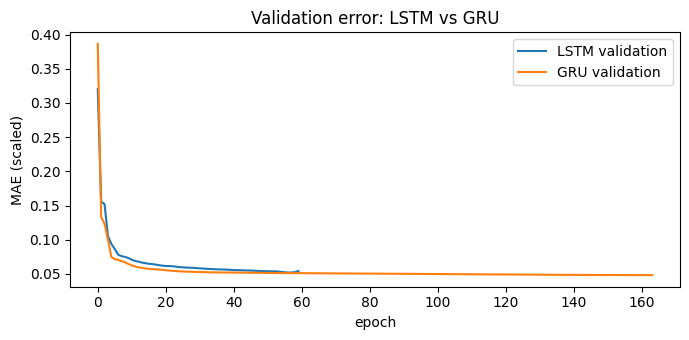

In [33]:
keras.utils.set_random_seed(SEED)

gru_model = keras.Sequential([
    keras.Input(shape=(INPUT_WINDOW, 1)),
    keras.layers.GRU(UNITS),          # the only change compared with the LSTM model
    keras.layers.Dense(H),            # 24 outputs = next 24 hours
])
gru_model.compile(optimizer="adam", loss="mae")

gru_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True,
)

gru_history = gru_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,                        # upper limit; early stopping decides when to stop
    batch_size=BATCH,
    shuffle=False,
    callbacks=[gru_early_stop],
    verbose=2,
)

# training curves of both models (validation error)
plt.figure(figsize=(7, 3.5))
plt.plot(history.history["val_loss"], label="LSTM validation")
plt.plot(gru_history.history["val_loss"], label="GRU validation")
plt.xlabel("epoch"); plt.ylabel("MAE (scaled)"); plt.title("Validation error: LSTM vs GRU"); plt.legend()
plt.tight_layout(); plt.show()

In [34]:
# predictions in EUR/MWh, saved to a separate file
GRU_FILE = "gru_predictions_validation.csv"            # columns: issue_time, timestamp, gru

gru_scaled = gru_model.predict(X_val, verbose=0)       # (days, 24)
gru_pred = scaler.inverse_transform(gru_scaled.reshape(-1, 1)).reshape(gru_scaled.shape)

rows = []
for T, values in zip(val_days, gru_pred):
    for k, v in enumerate(values):
        rows.append((T, T + pd.Timedelta(hours=k), float(v)))
gru_df = pd.DataFrame(rows, columns=["issue_time", "timestamp", "gru"])
gru_df.to_csv(GRU_FILE, index=False)

print("saved:", GRU_FILE, "| rows:", len(gru_df), "| forecast days:", gru_df["issue_time"].nunique())
gru_df.head(3)

saved: gru_predictions_validation.csv | rows: 8760 | forecast days: 365


,issue_time,timestamp,gru
0,2017-01-01 00:00:00+00:00,2017-01-01 00:00:00+00:00,62.136524
1,2017-01-01 00:00:00+00:00,2017-01-01 01:00:00+00:00,60.951279
2,2017-01-01 00:00:00+00:00,2017-01-01 02:00:00+00:00,59.197422


## Step 12 — Compare: baselines vs LSTM vs GRU | الخطوة 12 — المقارنة: الـ baselines مقابل LSTM و GRU

Same validation days, same horizon, same rows for every method. Metrics in EUR/MWh. **Lower is better.**

<div dir="rtl">

نفس أيام التحقق ونفس الأفق ونفس الصفوف لكل الطرق. المقاييس بوحدة EUR/MWh. **الأقل هو الأفضل.**

</div>

In [35]:
# one table with every method on exactly the same rows
all_df = lstm_df.merge(gru_df, on=["issue_time", "timestamp"], how="inner")
t_idx, i_idx = all_df["timestamp"], all_df["issue_time"]

cmp_all = pd.DataFrame({
    "actual":     price.reindex(t_idx).values,
    "last_value": price.reindex(i_idx - pd.Timedelta(hours=1)).values,     # last known price at 00:00
    "lag_24":     price.reindex(t_idx - pd.Timedelta(hours=24)).values,    # same hour yesterday
    "lag_168":    price.reindex(t_idx - pd.Timedelta(hours=168)).values,   # same hour last week
    "lstm":       all_df["lstm"].values,
    "gru":        all_df["gru"].values,
}).dropna()

METHODS = ["last_value", "lag_24", "lag_168", "lstm", "gru"]
scores = {}
for m in METHODS:
    err = cmp_all["actual"] - cmp_all[m]
    scores[m] = {"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean())}

final_table = pd.DataFrame(scores).T.round(2).sort_values("MAE")
final_table["MAE vs lag_24 (%)"] = ((1 - final_table["MAE"] / final_table.loc["lag_24", "MAE"]) * 100).round(1)
print("rows compared:", len(cmp_all))
final_table

rows compared: 8760


,MAE,RMSE,MAE vs lag_24 (%)
gru,4.49,6.24,13.5
lstm,4.85,6.54,6.6
lag_24,5.19,7.49,0.0
lag_168,6.27,8.88,-20.8
last_value,7.56,9.79,-45.7


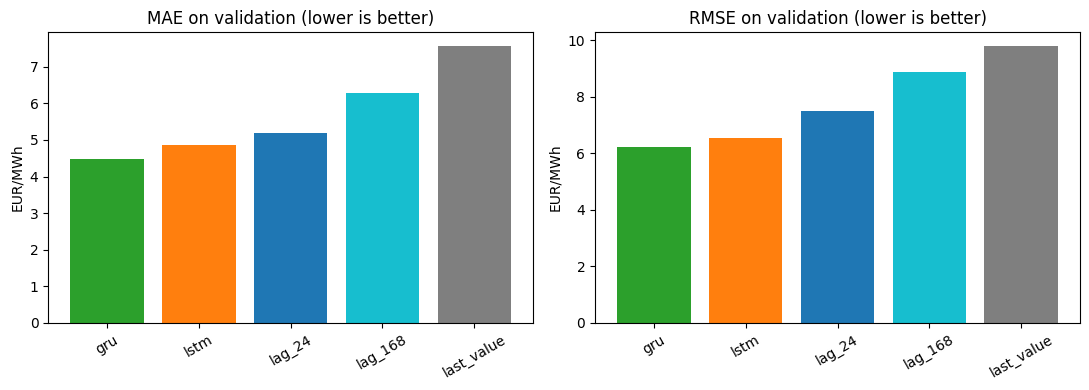

In [36]:
# bar chart: MAE and RMSE for every method
colors = {"last_value": "tab:gray", "lag_24": "tab:blue", "lag_168": "tab:cyan",
          "lstm": "tab:orange", "gru": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    vals = final_table[metric]
    ax.bar(vals.index, vals.values, color=[colors[m] for m in vals.index])
    ax.set_ylabel("EUR/MWh"); ax.set_title(f"{metric} on validation (lower is better)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

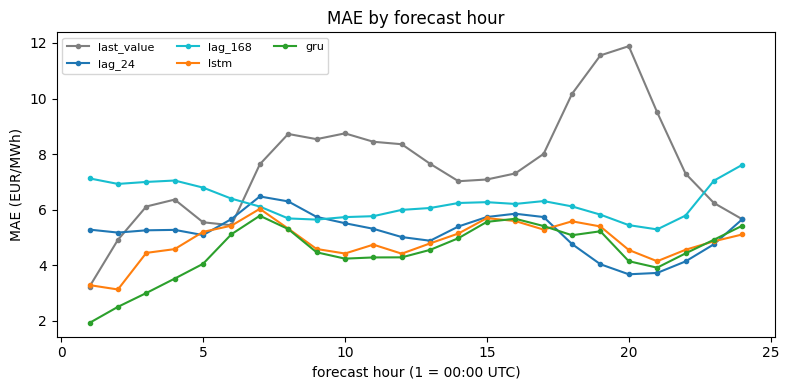

In [37]:
# MAE by forecast hour (1..24): who is better early or late in the day?
step = cmp_all.assign(step=np.tile(np.arange(1, H + 1), len(cmp_all) // H))
fig, ax = plt.subplots(figsize=(8, 4))
for m in METHODS:
    e = (step["actual"] - step[m]).abs().groupby(step["step"]).mean()
    ax.plot(e.index, e.values, marker="o", ms=3, label=m, color=colors[m])
ax.set_xlabel("forecast hour (1 = 00:00 UTC)"); ax.set_ylabel("MAE (EUR/MWh)")
ax.set_title("MAE by forecast hour"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

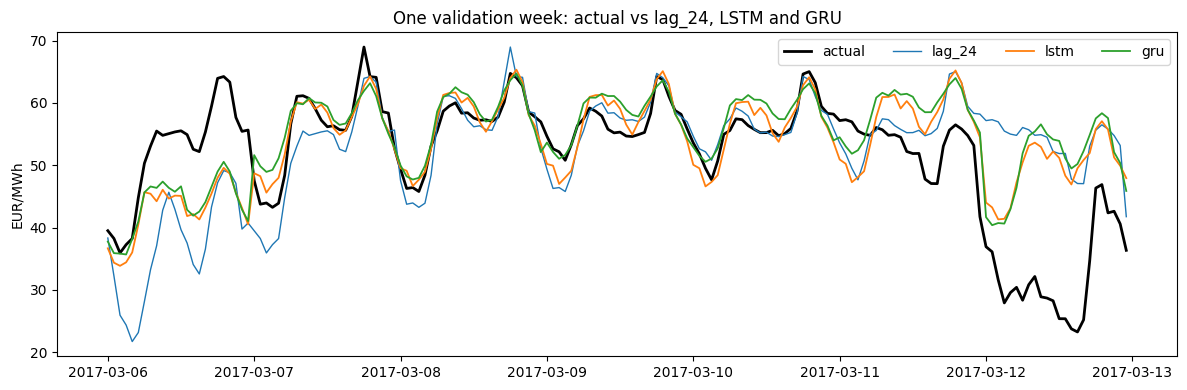

In [38]:
# one validation week: actual vs all methods
wk = all_df.copy()
wk["actual"]  = price.reindex(wk["timestamp"]).values
wk["lag_24"]  = price.reindex(wk["timestamp"] - pd.Timedelta(hours=24)).values
wk = wk[(wk["timestamp"] >= week_start) & (wk["timestamp"] < week_start + pd.Timedelta(days=7))]

plt.figure(figsize=(12, 4))
plt.plot(wk["timestamp"], wk["actual"], color="black", lw=2, label="actual")
plt.plot(wk["timestamp"], wk["lag_24"], lw=1, color=colors["lag_24"], label="lag_24")
plt.plot(wk["timestamp"], wk["lstm"],   lw=1.3, color=colors["lstm"], label="lstm")
plt.plot(wk["timestamp"], wk["gru"],    lw=1.3, color=colors["gru"],  label="gru")
plt.ylabel("EUR/MWh"); plt.title("One validation week: actual vs lag_24, LSTM and GRU"); plt.legend(ncol=4)
plt.tight_layout(); plt.show()

## Checklist | قائمة المراجعة

- [ ] Windows checked by hand: inputs before targets (Step 6). / فحص النوافذ يدويًا.
- [ ] Scaler fitted on the training period only (Step 4). / الـ scaler على التدريب فقط.
- [ ] Same forecast days as Track A: 2017-01-01 to 2017-12-31, 24 h each (Step 3). / نفس أيام Track A.
- [ ] `lstm_predictions_validation.csv` saved with `issue_time`, `timestamp`, `lstm` (Step 9). / تم حفظ الملف.
- [ ] Test period (2018) not used. / لم تُستخدم فترة الاختبار.
- [ ] Results reported honestly, even if `lag_24` is better. / النتائج بأمانة حتى لو `lag_24` أفضل.

**Next / الخطوة الجاية:** copy `lstm_predictions_validation.csv` to the folder of the Track A notebook and run its Step 10. / انسخي الملف إلى مجلد نوتبوك Track A وشغّلي الخطوة 10 فيه.